### Analisis Exploratorio de Datos (EDA) y Analisis comparativo

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
df = pd.read_excel('../data/processed/eventos_chubut_jujuy.xlsx')

In [71]:
df

,Unnamed: 0,noticia_id,provincia,localidad,actores_participantes,demanda_principal,tipo_accion,tipo_accion_detalle,disrupcion,escala,...,demanda_derechos_especificos,demanda_institucional,demanda_conmemoracion,tiene_marcha,tiene_corte,tiene_paro,tiene_acto,tiene_escrache,tiene_destrozos,tiene_toma
0,0,2021103100,Chubut,Chubut,Sindicato de la Salud Pública,Pago de deuda de paritarias y retroactivos,Paro,trabajo a reglamento,1.0,media,...,0,0,0,0,0,1,0,0,0,0
1,1,2021110100,Chubut,No especificado,No especificado,No especificado,No especificado,No especificado,99.0,No especificado,...,0,0,0,0,0,0,0,0,0,0
2,2,2021110200,Chubut,Rawson,Auxiliares de la educación,falta de convocatoria a paritarias salariales,Corte,Ruta provincial Nº 7,1.0,media,...,0,0,0,0,1,0,0,0,0,0
3,3,2021110202,Chubut,Esquel,Miembros de comunidades originarias,solución a la titularidad de tierras,Toma de edificio,ocupación del edificio del IAC,1.0,baja,...,0,0,0,0,0,0,0,0,0,1
4,4,2021110202,Chubut,Esquel,Miembros de comunidades originarias,No especificado,Toma de edificio,ocupación en la Secretaría de Bosques,1.0,baja,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,182,2023080101,Jujuy,CABA (fuera de Jujuy),Tercer Malón de la Paz,Contra Reforma / Por la Ley de Propiedad Comun...,Marcha,;ovilización / actividad de visibilización,0.0,Media,...,0,0,0,1,0,0,0,0,0,0
183,183,2023080102,Jujuy,San Salvador de Jujuy,Docentes(secundarios y terciarios),Salarial,Mixta,movilización mixta,1.0,Baja,...,0,0,0,0,0,0,0,0,0,0
184,184,2023080301,Jujuy,San Salvador de Jujuy,Docentes/ Gremios docentes,Salarial/ Derecho a protesta,Mixta,movilización / paro,1.0,Media,...,0,0,0,0,0,1,0,0,0,0
185,185,2023080501,Jujuy,San Salvador de Jujuy,La multisectorial,Contra Reforma/Salarial/ Apoyo Malón de la Paz,Marcha,marcha de antorchas,0.0,Alta,...,0,0,1,1,0,0,0,0,0,0


In [72]:
df.dtypes

Unnamed: 0                         int64
noticia_id                         int64
provincia                            str
localidad                            str
actores_participantes                str
demanda_principal                    str
tipo_accion                          str
tipo_accion_detalle                  str
disrupcion                       float64
escala                            object
intensidad                        object
respuesta_estatal                    str
presencia_policial               float64
accionar_policial                  int64
tipo_intervencion_estatal        float64
uso_fuerza                       float64
heridos                          float64
detenciones                      float64
judicializacion                  float64
coord_interinstitucional         float64
canales_informales               float64
amenaza_politica                 float64
resultado_episodio               float64
fuente                               str
observaciones   

In [73]:
df_ch = df[df["provincia"] == "Chubut"]
df_j  = df[df["provincia"] == "Jujuy"]

In [74]:
print(f"Chubut: {len(df_ch)} eventos")
print(f"Jujuy: {len(df_j)} eventos")

Chubut: 121 eventos
Jujuy: 66 eventos


La primer comparacion que se puede hacer es que Chubut supera en doble la cantidad de eventos que en jujuy

Ahora queremos comprobar la distribucion de eventos por localidad para cada provincia

In [75]:
print(df_ch["localidad"].value_counts().head(10))
print(df_j["localidad"].value_counts().head(10))

localidad
Rawson                26
Trelew                25
Chubut                16
Esquel                16
No especificado       10
Puerto Madryn          8
Madryn                 5
El Bolsón              3
Comodoro Rivadavia     2
Puerto Rawson          1
Name: count, dtype: int64
localidad
San Salvador de Jujuy            34
Varias localidades               19
Libertador General San Martín     2
Tilcara                           2
Abra Pampa                        1
Purmamarca                        1
San Pedro de Jujuy                1
Ruta (sin localidad puntual)      1
Sin datos                         1
Finca El Pongo                    1
Name: count, dtype: int64


Podemos observar en general que los eventos ocurren en las ciudades mas importantes de cada provincia
- Para el caso de chubut la concentracion esta en la capital (Rawson) con 26 eventos y en trelew con 25 eventos el rseto se reparten en Esquel, puerto madryn, El bolson (esto se puede dar porque la noticia se registro en un lugar limitrofe con chubut), tambien hay 16 noticias que registran el lugar como chubut, esto puede darse porque en la noticia no esta en que zona ocurrio con exactitud la noticia y solo pone como chubut
- Para el caso de Jujuy ocurre algo parecido casi la mitad de los eventos ocurren en la capital jujeña, el resto ocurre en multplies localidades

Veamos tambien el periodo que abarcan los eventos y cuantos hay por dia 

In [76]:
df["noticia_id"] = df["noticia_id"].astype(str)

df["anio"] = df["noticia_id"].str[:4]
df["mes"] = df["noticia_id"].str[:6]
df["anio_mes"] = df["noticia_id"].str[:6]

# Por provincia
df_ch = df[df["provincia"] == "Chubut"].copy()
df_j  = df[df["provincia"] == "Jujuy"].copy()

print("=== Chubut: eventos por mes ===")
print(df_ch["mes"].value_counts().sort_index())

print("\n=== Jujuy: eventos por mes ===")
print(df_j["mes"].value_counts().sort_index())

=== Chubut: eventos por mes ===
mes
202110     1
202111    39
202112    69
202201    12
Name: count, dtype: int64

=== Jujuy: eventos por mes ===
mes
202306    40
202307    21
202308     5
Name: count, dtype: int64


Para chubut el corpus de eventos comprend el periodo 2021/10 hasta el 2022/01 con el grueso de noticias en 2021/12.

para jujuy el corpus de eventos va entre el 2023/06 y 2023/08 con mayor intensidad de noticias para el 2023/06

Vamos a preparar las columnas de actores, demandas y acciones para cada provincia, esto se realizo a partir de una categorizacion boleana a partir de las columnas de demanda, actores y acciones para separar 

In [77]:
print("=== Tipo de accion ===")
print(df_ch['tipo_accion'].value_counts())
print("=== Tipo de accion ===")
print(df_j['tipo_accion'].value_counts())

=== Tipo de accion ===
tipo_accion
Marcha                    30
Manifestación             23
Corte                     13
Paro                      10
Acto                      10
No especificado            9
Otra                       5
Destrozos                  5
Mixta                      4
Escrache                   4
Toma de edificio           3
Asamblea                   3
Caravana                   1
Difusión de comunicado     1
Name: count, dtype: int64
=== Tipo de accion ===
tipo_accion
Marcha    30
Corte     14
Mixta     12
Otra       9
Acampe     1
Name: count, dtype: int64


Jujuy desplegó un repertorio de movilización masiva sostenida (marchas, cortes y paros todos más frecuentes). Chubut combinó movilización con acciones puntuales de confrontación (escrache, destrozos, tomas) que no aparecen en Jujuy. Esto refleja dos lógicas distintas: en Jujuy el conflicto se sostuvo en el tiempo con medidas de fuerza prolongadas (paro docente por tiempo indefinido), en Chubut hubo un pico acotado de confrontación 

In [78]:
print("=== Tipo de accion ===")
print(df_ch['tipo_accion'].value_counts())
print("=== Tipo de accion ===")
print(df_j['tipo_accion'].value_counts())

=== Tipo de accion ===
tipo_accion
Marcha                    30
Manifestación             23
Corte                     13
Paro                      10
Acto                      10
No especificado            9
Otra                       5
Destrozos                  5
Mixta                      4
Escrache                   4
Toma de edificio           3
Asamblea                   3
Caravana                   1
Difusión de comunicado     1
Name: count, dtype: int64
=== Tipo de accion ===
tipo_accion
Marcha    30
Corte     14
Mixta     12
Otra       9
Acampe     1
Name: count, dtype: int64


In [79]:
def armonizar(row):
    prov = row["provincia"]
    cod = row["tipo_intervencion_estatal"]
    if pd.isna(cod): return "Sin datos"
    cod = int(cod)
    if cod == 0: return "Ausencia"
    elif cod == 1: return "Monitoreo"
    elif cod == 2: return "Contención"
    elif cod == 3: return "Represión" if prov == "Chubut" else "Disuasión"
    elif cod == 4: return "Represión"
    else: return "Sin datos"

df["intervencion_armonizada"] = df.apply(armonizar, axis=1)
df["es_represion"] = (df["intervencion_armonizada"] == "Represión").astype(int)
df["mes"] = df["noticia_id"].astype(str).str[:6]

In [80]:
COLS_ACTORES = ["docentes", "gremios_estatales", "sindicatos_privados",
                "organizaciones_sociales", "comunidades_indigenas", "vecinos",
                "colectivos_ambientales", "colectivos_especificos",
                "partidos_politicos", "policias_actores",
                "publico_general", "colectivos_violentos", "otros"]

COLS_ACCION = ["tiene_marcha", "tiene_corte", "tiene_paro", "tiene_acto",
               "tiene_escrache", "tiene_destrozos", "tiene_toma"]

CATS_INTERV = ["Ausencia", "Monitoreo", "Contención", "Disuasión", "Represión", "Sin datos"]

COLS_DEMANDAS = ["demanda_salarial", "demanda_laboral", "demanda_ambiental_territorial",
                 "demanda_politica_legal", "demanda_ddhh", "demanda_servicios",
                 "demanda_derechos_especificos", "demanda_institucional",
                 "demanda_conmemoracion"]

In [81]:
def tabla_accion_intervencion(prov):
    sub = df[df["provincia"] == prov]
    filas = []
    for accion in COLS_ACCION:
        sub_acc = sub[sub[accion] == 1]
        n = len(sub_acc)
        conteo = sub_acc["intervencion_armonizada"].value_counts().to_dict()
        fila = {"acción": accion.replace("tiene_", ""), "n": n}
        fila.update({k: conteo.get(k, 0) for k in CATS_INTERV})
        filas.append(fila)
    return pd.DataFrame(filas).set_index("acción")


def tabla_actor_represion(prov):
    sub = df[df["provincia"] == prov]
    filas = []
    for actor in COLS_ACTORES:
        sub_act = sub[sub[actor] == 1]
        n = len(sub_act)
        n_rep = sub_act["es_represion"].sum()
        filas.append({"actor": actor, "n": n, "n_rep": n_rep,
                        "%_rep": round(n_rep/n*100, 1)})
    return pd.DataFrame(filas).set_index("actor")


def tabla_actor_accion(prov):
    sub = df[df["provincia"] == prov]
    filas = []
    for actor in COLS_ACTORES:
        sub_act = sub[sub[actor] == 1]
        fila = {a.replace("tiene_", ""): sub_act[a].sum() for a in COLS_ACCION}
        fila["n"] = len(sub_act)
        filas.append({"actor": actor, **fila})
    return pd.DataFrame(filas).set_index("actor")


def tabla_demanda_accion(prov):
    sub = df[df["provincia"] == prov]
    filas = []
    for dem in COLS_DEMANDAS:
        sub_dem = sub[sub[dem] == 1]
        fila = {a.replace("tiene_", ""): sub_dem[a].sum() for a in COLS_ACCION}
        fila["n"] = len(sub_dem)
        filas.append({"demanda": dem.replace("demanda_", ""), **fila})
    return pd.DataFrame(filas).set_index("demanda")


def tabla_demanda_intervencion(prov):
    sub = df[df["provincia"] == prov]
    filas = []
    for dem in COLS_DEMANDAS:
        sub_dem = sub[sub[dem] == 1]
        n = len(sub_dem)
        conteo = sub_dem["intervencion_armonizada"].value_counts().to_dict()
        fila = {"demanda": dem.replace("demanda_", ""), "n": n}
        fila.update({k: conteo.get(k, 0) for k in CATS_INTERV})
        filas.append(fila)
    return pd.DataFrame(filas).set_index("demanda")

In [82]:
def tabla_accion_intervencion(prov):
    """Tipo de acción × Intervención estatal para una provincia."""
    sub = df[df["provincia"] == prov]
    filas = []
    for accion in COLS_ACCION:
        sub_acc = sub[sub[accion] == 1]
        n = len(sub_acc)
        conteo = sub_acc["intervencion_armonizada"].value_counts().to_dict()
        fila = {"acción": accion.replace("tiene_", ""), "n": n}
        fila.update({k: conteo.get(k, 0) for k in CATS_INTERV})
        filas.append(fila)
    return pd.DataFrame(filas).set_index("acción")


def tabla_actor_represion(prov):
    """Actor × % represión para una provincia."""
    sub = df[df["provincia"] == prov]
    filas = []
    for actor in COLS_ACTORES:
        sub_act = sub[sub[actor] == 1]
        n = len(sub_act)
        n_rep = sub_act["es_represion"].sum()
        filas.append({
            "actor": actor, "n": n, "n_rep": n_rep,
            "%_rep": round(n_rep/n*100, 1)
        })
    return pd.DataFrame(filas).set_index("actor")


def tabla_actor_accion(prov):
    """Actor × Tipo de acción (booleanos) para una provincia."""
    sub = df[df["provincia"] == prov]
    filas = []
    for actor in COLS_ACTORES:
        sub_act = sub[sub[actor] == 1]
        fila = {a.replace("tiene_", ""): sub_act[a].sum() for a in COLS_ACCION}
        fila["n"] = len(sub_act)
        filas.append({"actor": actor, **fila})
    return pd.DataFrame(filas).set_index("actor")


def tabla_demanda_accion(prov):
    """Demanda × Tipo de acción (booleanos) para una provincia."""
    sub = df[df["provincia"] == prov]
    filas = []
    for dem in COLS_DEMANDAS:
        sub_dem = sub[sub[dem] == 1]
        fila = {a.replace("tiene_", ""): sub_dem[a].sum() for a in COLS_ACCION}
        fila["n"] = len(sub_dem)
        filas.append({"demanda": dem.replace("demanda_", ""), **fila})
    return pd.DataFrame(filas).set_index("demanda")

In [83]:
print("=" * 60)
print("TAMAÑO DE LOS CORPUS")
print("=" * 60)
print(df["provincia"].value_counts().to_string())

print("\n" + "=" * 60)
print("DISTRIBUCIÓN TEMPORAL")
print("=" * 60)
print(pd.crosstab(df["mes"], df["provincia"]).to_string())

print("\n" + "=" * 60)
print("TOP 5 LOCALIDADES POR PROVINCIA")
print("=" * 60)
for prov in ["Chubut", "Jujuy"]:
    print(f"\n--- {prov} ---")
    print(df[df["provincia"] == prov]["localidad"].value_counts().head(5).to_string())

TAMAÑO DE LOS CORPUS
provincia
Chubut    121
Jujuy      66

DISTRIBUCIÓN TEMPORAL
provincia  Chubut  Jujuy
mes                     
202110          1      0
202111         39      0
202112         69      0
202201         12      0
202306          0     40
202307          0     21
202308          0      5

TOP 5 LOCALIDADES POR PROVINCIA

--- Chubut ---
localidad
Rawson             26
Trelew             25
Chubut             16
Esquel             16
No especificado    10

--- Jujuy ---
localidad
San Salvador de Jujuy            34
Varias localidades               19
Libertador General San Martín     2
Tilcara                           2
Abra Pampa                        1



=== Booleanos de acción ===
provincia        Chubut  Jujuy  diferencia
tiene_paro          8.3   21.2        12.9
tiene_corte        10.7   21.2        10.5
tiene_marcha       44.6   54.5         9.9
tiene_toma          2.5    0.0        -2.5
tiene_escrache      3.3    0.0        -3.3
tiene_destrozos     4.1    0.0        -4.1
tiene_acto         10.7    4.5        -6.2


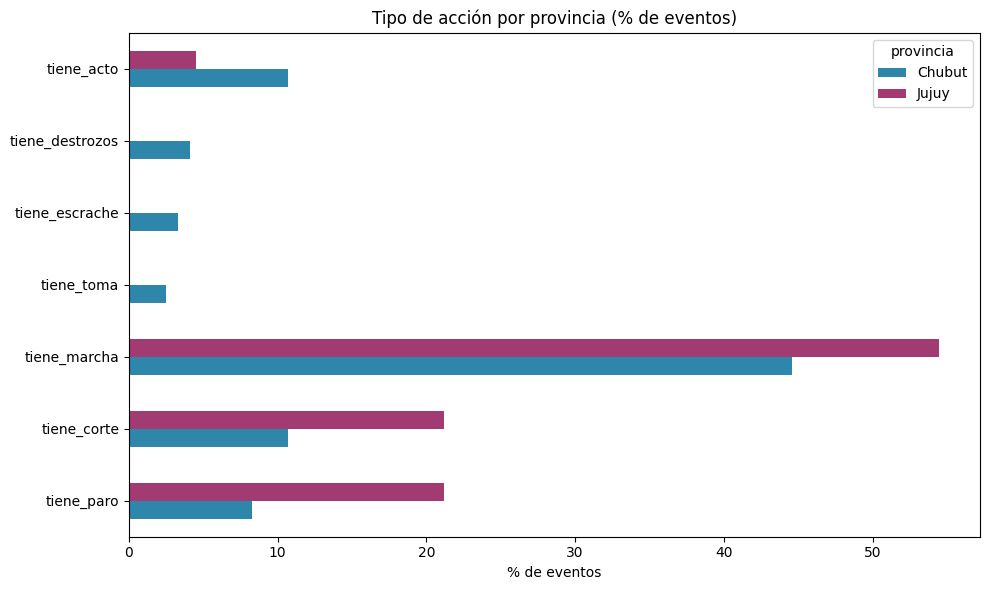

In [84]:
comparacion_accion = df.groupby("provincia")[COLS_ACCION].mean() * 100
comparacion_accion = comparacion_accion.round(1).T
comparacion_accion["diferencia"] = comparacion_accion["Jujuy"] - comparacion_accion["Chubut"]
comparacion_accion = comparacion_accion.sort_values("diferencia", ascending=False)
print("\n=== Booleanos de acción ===")
print(comparacion_accion.to_string())

comparacion_accion[["Chubut", "Jujuy"]].plot(kind="barh", figsize=(10, 6),
                                              color=["#2E86AB", "#A23B72"])
plt.title("Tipo de acción por provincia (% de eventos)")
plt.xlabel("% de eventos")
plt.tight_layout()
plt.show()

ACTORES POR PROVINCIA (% de eventos)
provincia                Chubut  Jujuy  diferencia
docentes                    1.7   62.1        60.4
organizaciones_sociales     4.1   30.3        26.2
comunidades_indigenas       5.0   27.3        22.3
gremios_estatales          14.9   19.7         4.8
colectivos_especificos      1.7    4.5         2.8
otros                       0.8    0.0        -0.8
partidos_politicos          4.1    1.5        -2.6
publico_general            10.7    7.6        -3.1
sindicatos_privados        11.6    7.6        -4.0
vecinos                    20.7   16.7        -4.0
colectivos_violentos        5.0    0.0        -5.0
policias_actores            7.4    0.0        -7.4
colectivos_ambientales     13.2    0.0       -13.2


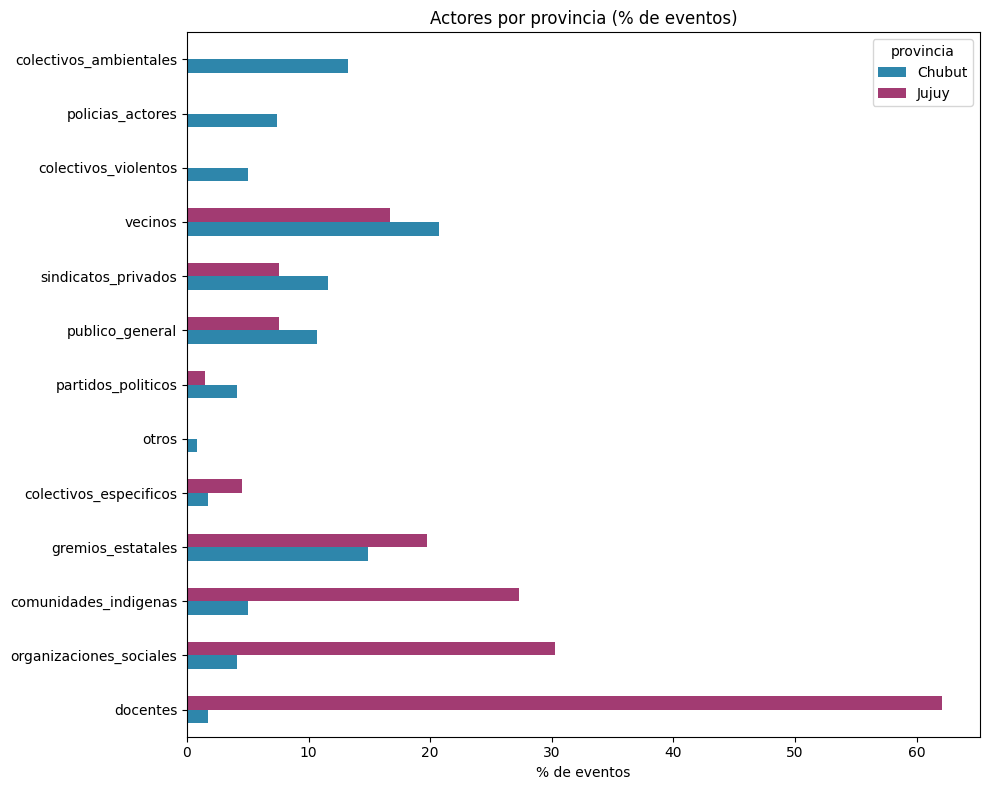

In [85]:
print("=" * 60)
print("ACTORES POR PROVINCIA (% de eventos)")
print("=" * 60)

comparacion_actores = df.groupby("provincia")[COLS_ACTORES].mean() * 100
comparacion_actores = comparacion_actores.round(1).T
comparacion_actores["diferencia"] = comparacion_actores["Jujuy"] - comparacion_actores["Chubut"]
comparacion_actores = comparacion_actores.sort_values("diferencia", ascending=False)
print(comparacion_actores.to_string())

comparacion_actores[["Chubut", "Jujuy"]].plot(kind="barh", figsize=(10, 8),
                                               color=["#2E86AB", "#A23B72"])
plt.title("Actores por provincia (% de eventos)")
plt.xlabel("% de eventos")
plt.tight_layout()
plt.show()

Jujuy fue un conflicto gremial-docente con fuerte presencia de organizaciones sociales y comunidades indígenas. El 62% de los eventos tuvieron docentes como actores, consistente con el paro docente que se extendió por semanas.

Chubut fue un conflicto territorial-ambiental con vecinos y colectivos ambientales. El 13.2% de los eventos tuvieron colectivos ambientales (antimineros, asambleístas), categoría ausente en Jujuy.

Chubut tuvo dos actores exclusivos: policías como manifestantes (7.4%, protestas salariales de CoBiPol) y colectivos violentos (5%, encapuchados y vándalos del pico diciembre).

Comunidades indígenas: presentes en ambos, pero con mucho más peso en Jujuy (27.3%) que en Chubut (5%).

DEMANDAS POR PROVINCIA (% de eventos)
provincia                      Chubut  Jujuy  diferencia
demanda_politica_legal           10.7   59.1        48.4
demanda_salarial                 23.1   59.1        36.0
demanda_conmemoracion             0.0    4.5         4.5
demanda_ddhh                      9.9   12.1         2.2
demanda_derechos_especificos      4.1    4.5         0.4
demanda_laboral                   6.6    4.5        -2.1
demanda_servicios                 2.5    0.0        -2.5
demanda_institucional             5.0    1.5        -3.5
demanda_ambiental_territorial    33.1    3.0       -30.1


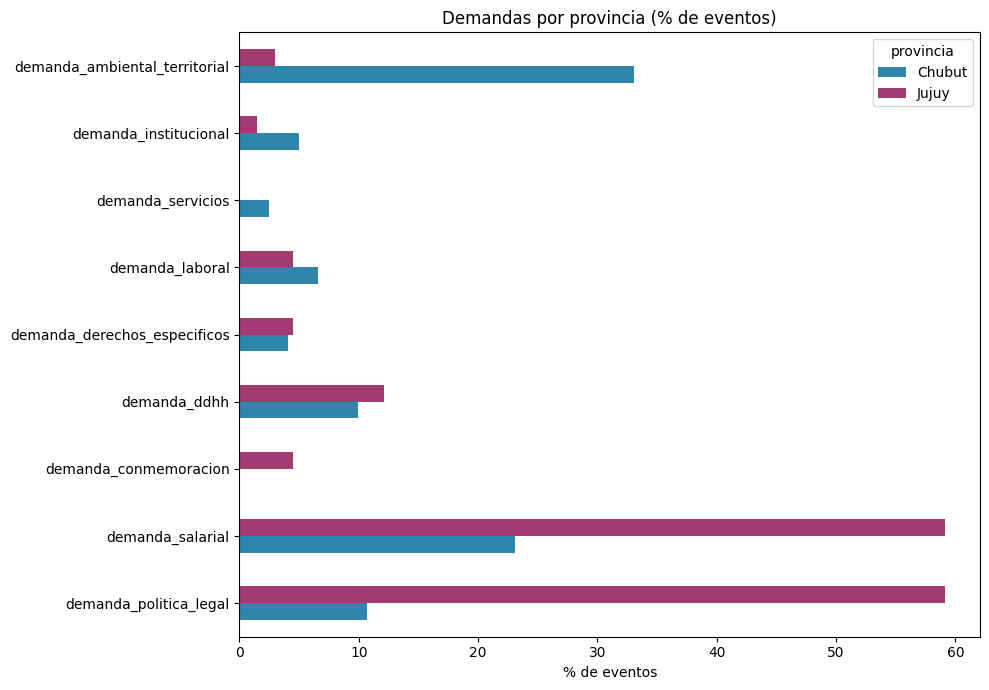


=== Promedio de demandas por evento ===
           count  mean   std  min  25%  50%  75%  max
provincia                                            
Chubut     121.0  0.95  0.64  0.0  1.0  1.0  1.0  3.0
Jujuy       66.0  1.48  0.83  0.0  1.0  1.0  2.0  4.0


In [86]:
print("=" * 60)
print("DEMANDAS POR PROVINCIA (% de eventos)")
print("=" * 60)

comparacion_demandas = df.groupby("provincia")[COLS_DEMANDAS].mean() * 100
comparacion_demandas = comparacion_demandas.round(1).T
comparacion_demandas["diferencia"] = comparacion_demandas["Jujuy"] - comparacion_demandas["Chubut"]
comparacion_demandas = comparacion_demandas.sort_values("diferencia", ascending=False)
print(comparacion_demandas.to_string())

comparacion_demandas[["Chubut", "Jujuy"]].plot(kind="barh", figsize=(10, 7),
                                                color=["#2E86AB", "#A23B72"])
plt.title("Demandas por provincia (% de eventos)")
plt.xlabel("% de eventos")
plt.tight_layout()
# plt.savefig("../outputs/graficos/comparativo_demandas.png", dpi=150)
plt.show()

# Promedio de demandas por evento
df["n_demandas"] = df[COLS_DEMANDAS].sum(axis=1)
print("\n=== Promedio de demandas por evento ===")
print(df.groupby("provincia")["n_demandas"].describe().round(2).to_string())

Jujuy combinó demanda política y salarial en el mismo conflicto. El 59% de los eventos tuvieron demanda política (contra la reforma constitucional) y otro 59% demanda salarial (paritarias docentes). Eso significa que muchos eventos combinaban ambas.

Chubut tuvo un eje ambiental-territorial dominante (33%). La demanda anti-minería fue el eje del conflicto, con el componente salarial (23%) como eje secundario.

Promedio de demandas por evento: Chubut 0.95, Jujuy 1.48. Los eventos de Jujuy tienen más demandas superpuestas; los de Chubut son más específicos

INTERVENCIÓN ESTATAL POR PROVINCIA (%)
intervencion_armonizada  Ausencia  Monitoreo  Contención  Disuasión  Represión  Sin datos
provincia                                                                                
Chubut                       56.2        7.4         7.4        0.0        4.1       24.8
Jujuy                        50.0       13.6         6.1        3.0        7.6       19.7


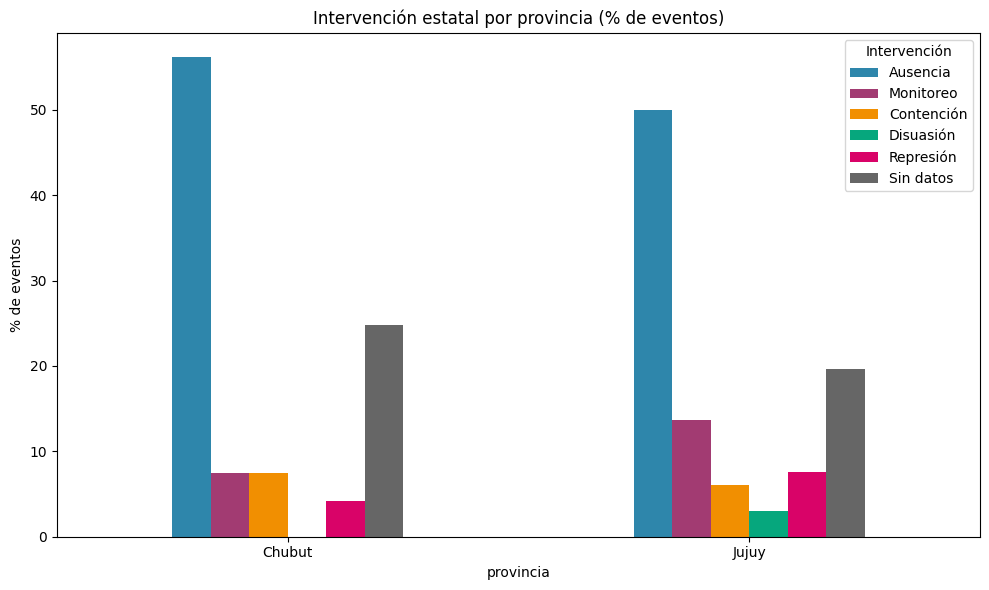

In [87]:
print("=" * 60)
print("INTERVENCIÓN ESTATAL POR PROVINCIA (%)")
print("=" * 60)

ct_int = pd.crosstab(df["provincia"], df["intervencion_armonizada"], normalize="index") * 100
ct_int = ct_int.reindex(columns=[c for c in CATS_INTERV if c in ct_int.columns], fill_value=0)
print(ct_int.round(1).to_string())

ct_int.plot(kind="bar", figsize=(10, 6), color=["#2E86AB", "#A23B72", "#F18F01", "#06A77D", "#D90368", "#666"])
plt.title("Intervención estatal por provincia (% de eventos)")
plt.ylabel("% de eventos")
plt.xticks(rotation=0)
plt.legend(title="Intervención", bbox_to_anchor=(1, 1))
plt.tight_layout()
# plt.savefig("../outputs/graficos/comparativo_intervencion.png", dpi=150)
plt.show()

Jujuy tuvo mayor presencia policial activa: monitoreo (13.6% vs 7.4%) y represión (7.6% vs 4.1%) son más frecuentes.

La disuasión (3%) es exclusiva de Jujuy, categoría ausente en el libro de códigos de Chubut.

Chubut tiene más "sin datos" (24.8% vs 19.7%), reflejando menor cobertura de la respuesta estatal por parte de la fuente periodística.

In [88]:
print("=" * 70)
print("CROSSTAB 1: TIPO DE ACCIÓN × INTERVENCIÓN ESTATAL")
print("=" * 70)

for prov in ["Chubut", "Jujuy"]:
    print(f"\n=== {prov} ===")
    print(tabla_accion_intervencion(prov).to_string())

CROSSTAB 1: TIPO DE ACCIÓN × INTERVENCIÓN ESTATAL

=== Chubut ===
            n  Ausencia  Monitoreo  Contención  Disuasión  Represión  Sin datos
acción                                                                         
marcha     54        31          3           6          0          2         12
corte      13         8          2           1          0          1          1
paro       10         9          0           0          0          0          1
acto       13         9          1           0          0          1          2
escrache    4         2          0           0          0          0          2
destrozos   5         3          0           2          0          0          0
toma        3         2          1           0          0          0          0

=== Jujuy ===
            n  Ausencia  Monitoreo  Contención  Disuasión  Represión  Sin datos
acción                                                                         
marcha     36        23          4     

El corte de ruta en Jujuy  más reprimido que en Chubut (28.6% vs 7.7%).

En Jujuy, de 14 eventos con corte, 4 tuvieron represión y 2 tuvieron disuasión. Es decir, el 42.9% de los cortes recibió algún tipo de intervención estatal activa.

En Chubut, de 13 cortes, solo 1 tuvo represión. El 61.5% de los cortes tuvieron ausencia estatal.

En Jujuy, la reforma constitucional buscaba precisamente prohibir los cortes de ruta, por lo que el Estado tenía incentivos directos para reprimirlos. En Chubut, el corte era una táctica más dentro de un repertorio amplio y no constituía el objeto del conflicto.

Los paros no reciben represión en ninguna provincia (0/10 Chubut, 0/14 Jujuy). La represión se dirige a la acción en la vía pública, no a medidas de fuerza gremial.

In [89]:
print("=" * 70)
print("CROSSTAB 2: ACTOR × REPRESIÓN")
print("=" * 70)

for prov in ["Chubut", "Jujuy"]:
    print(f"\n=== {prov} ===")
    print(tabla_actor_represion(prov).to_string())

CROSSTAB 2: ACTOR × REPRESIÓN

=== Chubut ===
                          n  n_rep  %_rep
actor                                    
docentes                  2      0    0.0
gremios_estatales        18      0    0.0
sindicatos_privados      14      2   14.3
organizaciones_sociales   5      0    0.0
comunidades_indigenas     6      0    0.0
vecinos                  25      0    0.0
colectivos_ambientales   16      3   18.8
colectivos_especificos    2      0    0.0
partidos_politicos        5      1   20.0
policias_actores          9      0    0.0
publico_general          13      1    7.7
colectivos_violentos      6      0    0.0
otros                     1      0    0.0

=== Jujuy ===
                          n  n_rep  %_rep
actor                                    
docentes                 41      3    7.3
gremios_estatales        13      0    0.0
sindicatos_privados       5      0    0.0
organizaciones_sociales  20      3   15.0
comunidades_indigenas    18      5   27.8
vecinos        

C:\Users\Federico\AppData\Local\Temp\ipykernel_18436\2521242718.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "%_rep": round(n_rep/n*100, 1)


 en Jujuy, las comunidades indígenas fueron el actor más reprimido (27.8%), seguido de organizaciones sociales (15%). En Chubut, los colectivos ambientales (18.8%) y partidos políticos (20%) fueron los más afectados, aunque con n muy chico (3-5 eventos).

In [90]:
print("=" * 70)
print("CROSSTAB 3: ACTOR × TIPO DE ACCIÓN")
print("=" * 70)

for prov in ["Chubut", "Jujuy"]:
    print(f"\n=== {prov} ===")
    print(tabla_actor_accion(prov).to_string())

CROSSTAB 3: ACTOR × TIPO DE ACCIÓN

=== Chubut ===
                         marcha  corte  paro  acto  escrache  destrozos  toma   n
actor                                                                            
docentes                      0      1     0     0         0          0     0   2
gremios_estatales             2      3     9     4         0          0     0  18
sindicatos_privados           4      2     2     1         4          0     0  14
organizaciones_sociales       4      0     0     0         0          0     0   5
comunidades_indigenas         3      0     0     0         0          0     3   6
vecinos                      19      4     0     1         0          0     0  25
colectivos_ambientales        8      1     0     1         4          0     0  16
colectivos_especificos        2      0     0     0         0          0     0   2
partidos_politicos            1      0     0     2         0          1     0   5
policias_actores              6      0     0   

In [91]:
print("=" * 70)
print("CROSSTAB 4: DEMANDA × TIPO DE ACCIÓN")
print("=" * 70)

for prov in ["Chubut", "Jujuy"]:
    print(f"\n=== {prov} ===")
    print(tabla_demanda_accion(prov).to_string())

CROSSTAB 4: DEMANDA × TIPO DE ACCIÓN

=== Chubut ===
                       marcha  corte  paro  acto  escrache  destrozos  toma   n
demanda                                                                        
salarial                    5      6     9     5         0          0     0  28
laboral                     3      0     3     1         0          0     0   8
ambiental_territorial      25      4     0     1         3          2     2  40
politica_legal              7      2     0     1         0          1     0  13
ddhh                        8      1     0     1         1          0     0  12
servicios                   2      1     0     0         0          0     0   3
derechos_especificos        5      0     0     0         0          0     0   5
institucional               4      0     0     1         0          0     0   6
conmemoracion               0      0     0     0         0          0     0   0

=== Jujuy ===
                       marcha  corte  paro  acto  es

In [92]:
print("=" * 70)
print("CROSSTAB 5: DEMANDA × INTERVENCIÓN ESTATAL")
print("=" * 70)

for prov in ["Chubut", "Jujuy"]:
    print(f"\n=== {prov} ===")
    print(tabla_demanda_intervencion(prov).to_string())

CROSSTAB 5: DEMANDA × INTERVENCIÓN ESTATAL

=== Chubut ===
                        n  Ausencia  Monitoreo  Contención  Disuasión  Represión  Sin datos
demanda                                                                                    
salarial               28        20          3           1          0          0          4
laboral                 8         6          1           0          0          0          1
ambiental_territorial  40        22          2           5          0          3          8
politica_legal         13         7          0           0          0          2          4
ddhh                   12         6          1           1          0          0          4
servicios               3         2          1           0          0          0          0
derechos_especificos    5         4          1           0          0          0          0
institucional           6         5          1           0          0          0          0
conmemoracion        

C:\Users\Federico\AppData\Local\Temp\ipykernel_18436\1777492756.py:16: RuntimeWarning: invalid value encountered in scalar divide
  "%_rep": round(n_rep/n*100, 1)


CROSSTAB 6: % REPRESIÓN POR TIPO DE ACCIÓN Y PROVINCIA

=== % de represión ===
provincia  Chubut  Jujuy
acción                  
acto          7.7    0.0
corte         7.7   28.6
destrozos     0.0    NaN
escrache      0.0    NaN
marcha        3.7    2.8
paro          0.0    0.0
toma          0.0    NaN

=== Detalle ===
   acción provincia  n  n_rep  %_rep
   marcha    Chubut 54      2    3.7
    corte    Chubut 13      1    7.7
     paro    Chubut 10      0    0.0
     acto    Chubut 13      1    7.7
 escrache    Chubut  4      0    0.0
destrozos    Chubut  5      0    0.0
     toma    Chubut  3      0    0.0
   marcha     Jujuy 36      1    2.8
    corte     Jujuy 14      4   28.6
     paro     Jujuy 14      0    0.0
     acto     Jujuy  3      0    0.0
 escrache     Jujuy  0      0    NaN
destrozos     Jujuy  0      0    NaN
     toma     Jujuy  0      0    NaN


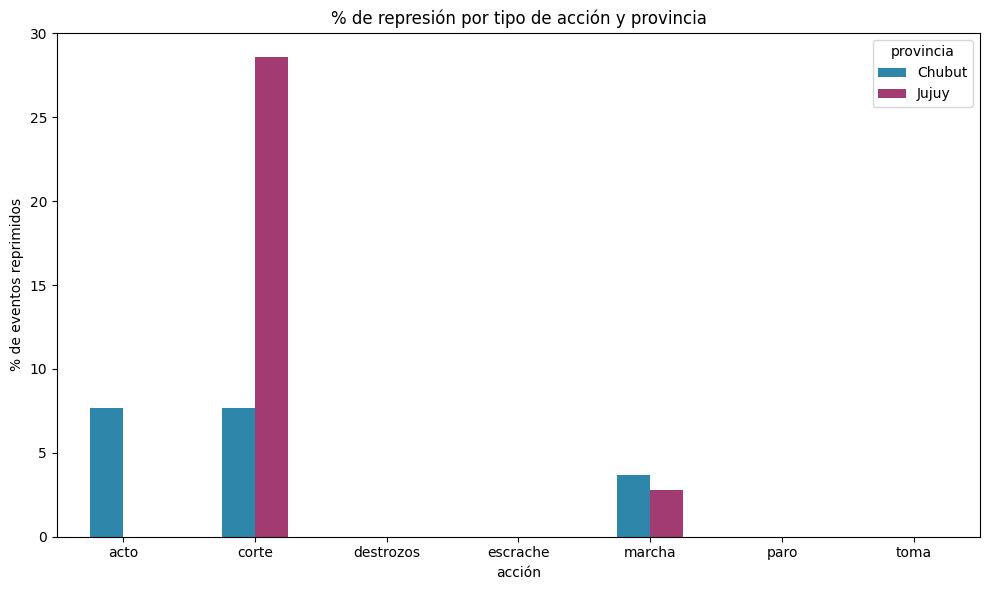

In [93]:
print("=" * 70)
print("CROSSTAB 6: % REPRESIÓN POR TIPO DE ACCIÓN Y PROVINCIA")
print("=" * 70)

resultado = []
for prov in ["Chubut", "Jujuy"]:
    sub = df[df["provincia"] == prov]
    for accion in COLS_ACCION:
        sub_acc = sub[sub[accion] == 1]
        n = len(sub_acc)
        n_rep = sub_acc["es_represion"].sum()
        resultado.append({
            "acción": accion.replace("tiene_", ""),
            "provincia": prov,
            "n": n, "n_rep": n_rep,
            "%_rep": round(n_rep/n*100, 1)
        })

res_df = pd.DataFrame(resultado)
pivot = res_df.pivot(index="acción", columns="provincia", values="%_rep")
print("\n=== % de represión ===")
print(pivot.round(1).to_string())

print("\n=== Detalle ===")
print(res_df.to_string(index=False))

# Gráfico
if len(res_df) > 0:
    pivot.plot(kind="bar", figsize=(10, 6), color=["#2E86AB", "#A23B72"])
    plt.title("% de represión por tipo de acción y provincia")
    plt.ylabel("% de eventos reprimidos")
    plt.xticks(rotation=0)
    plt.tight_layout()
    # plt.savefig("../outputs/graficos/comparativo_accion_represion.png", dpi=150)
    plt.show()

In [94]:
print("=" * 70)
print("CROSSTAB 7: MES × INTERVENCIÓN ESTATAL")
print("=" * 70)

for prov in ["Chubut", "Jujuy"]:
    print(f"\n=== {prov} ===")
    sub = df[df["provincia"] == prov]
    ct = pd.crosstab(sub["mes"], sub["intervencion_armonizada"])
    ct = ct.reindex(columns=[c for c in CATS_INTERV if c in ct.columns], fill_value=0)
    print(ct.to_string())

CROSSTAB 7: MES × INTERVENCIÓN ESTATAL

=== Chubut ===
intervencion_armonizada  Ausencia  Monitoreo  Contención  Represión  Sin datos
mes                                                                           
202110                          0          0           0          0          1
202111                         23          6           2          1          7
202112                         42          3           3          4         17
202201                          3          0           4          0          5

=== Jujuy ===
intervencion_armonizada  Ausencia  Monitoreo  Contención  Disuasión  Represión  Sin datos
mes                                                                                      
202306                         19          5           3          2          5          6
202307                          9          4           1          0          0          7
202308                          5          0           0          0          0          0


In [95]:
print("=" * 70)
print("CROSSTAB 8: LOCALIDAD × INTERVENCIÓN ESTATAL")
print("=" * 70)

for prov in ["Chubut", "Jujuy"]:
    print(f"\n=== {prov} ===")
    sub = df[df["provincia"] == prov]
    top_loc = sub["localidad"].value_counts().head(6).index
    ct = pd.crosstab(
        sub[sub["localidad"].isin(top_loc)]["localidad"],
        sub[sub["localidad"].isin(top_loc)]["intervencion_armonizada"]
    )
    ct = ct.reindex(columns=[c for c in CATS_INTERV if c in ct.columns], fill_value=0)
    print(ct.to_string())

CROSSTAB 8: LOCALIDAD × INTERVENCIÓN ESTATAL

=== Chubut ===
intervencion_armonizada  Ausencia  Monitoreo  Contención  Represión  Sin datos
localidad                                                                     
Chubut                         10          0           2          0          4
Esquel                          9          4           1          0          2
No especificado                 2          0           0          0          8
Puerto Madryn                   7          0           0          0          1
Rawson                         12          1           3          3          7
Trelew                         14          2           2          1          6

=== Jujuy ===
intervencion_armonizada        Ausencia  Monitoreo  Contención  Disuasión  Represión  Sin datos
localidad                                                                                      
Abra Pampa                            1          0           0          0          0          0
Libe